# Lezione: Tokenizzazione in Python



### Obiettivi
Alla fine della lezione saprete:
- distinguere testo, token, occorrenze e tipi;
- spiegare perché la tokenizzazione dipende dalla lingua e dal compito;
- confrontare `split()`, regole esplicite e tokenizer di libreria;
- riconoscere le scelte di normalizzazione e i loro effetti;
- descrivere parole fuori vocabolario e unità subword;
- analizzare gli errori di un tokenizer senza trattarlo come un oracolo.

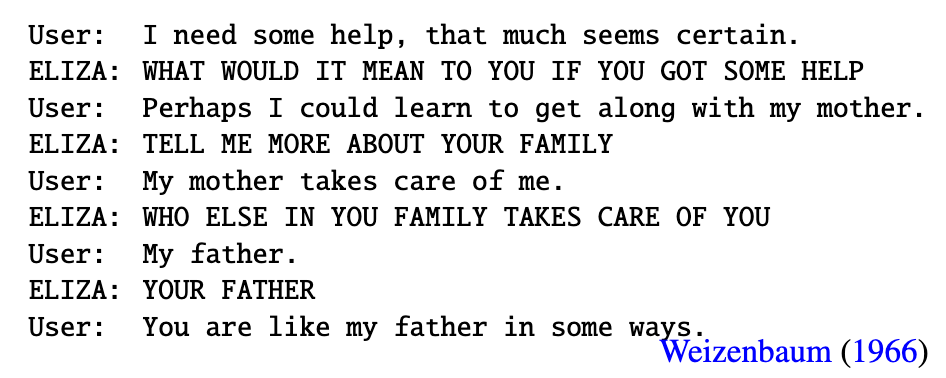

Il dialogo mostrato nell'immagine viene da ELIZA, un programma del 1966 che imitava un colloquio psicoterapeutico. I suoi pattern riconoscevano sequenze di parole nell'input e producevano risposte predefinite. Il sistema non comprendeva il testo, ma il suo comportamento dipendeva comunque da come l'input veniva suddiviso e riconosciuto.


## Cos'è la tokenizzazione?

La **tokenizzazione** trasforma una sequenza di testo in unità, dette *token*, secondo una convenzione scelta per un compito. Un token può essere una frase, una parola, un segno di punteggiatura, un carattere o una sequenza subword: non esiste una sola suddivisione corretta per tutti gli usi.

**Esempio:**

- Testo: "Ciao, come va?"
- Token (parole): ["Ciao", ",", "come", "va", "?"]

Per esempio, `Ciao, come va?` può diventare una sequenza di parole con la punteggiatura separata, ma un sistema che cerca soltanto parole potrebbe scartare i segni. La scelta cambia i dati che riceverà il modello.

Una distinzione utile: **tokenizzazione** decide i confini; **normalizzazione** trasforma le forme (per esempio, maiuscole/minuscole). Sono operazioni collegate, ma non equivalenti. Nel seguito useremo tokenizzazione a parole, salvo quando specifichiamo altro.

## Tokenizzazione base con `split()`

Il metodo più semplice per tokenizzare un testo è usare il metodo `.split()` delle stringhe.

In [ ]:
testo = "Ciao, come va oggi?"
tokens = testo.split()
print(tokens)

### Limiti di `.split()`

`split()` senza argomenti separa dove trova sequenze di spazi bianchi; non applica regole linguistiche. Per `Ciao, come va oggi?` restituisce `['Ciao,', 'come', 'va', 'oggi?']`.

Limiti da osservare:
- virgole e punti interrogativi restano attaccati alle parole;
- apostrofi, trattini, abbreviazioni (`dott.`) e indirizzi web richiedono convenzioni;
- più parole ortografiche possono formare un nome (`New York`), mentre forme come `l'acqua` possono essere tenute unite o separate;
- gli spazi non delimitano sempre parole: in cinese e giapponese la segmentazione richiede regole o modelli specifici.

Quindi `split()` è un punto di partenza utile per imparare, non un tokenizer linguistico generale. **Domanda alla classe:** quale uscita sarebbe più utile per un conteggio delle parole, e quale per un sistema che legge il tono della punteggiatura?

### Dalle regole al tokenizer dimostrazione

Una prima regola esplicita: trova sequenze di lettere/numeri e trattieni un apostrofo interno, oppure restituisci la punteggiatura come token separato. `re` fa parte della libreria standard di Python, quindi non richiede installazioni.

Questo esempio è volutamente piccolo: non è un tokenizer italiano completo. In particolare, le regole per date, decimali, abbreviazioni, emoji e URL richiedono decisioni aggiuntive.

In [ ]:
import re

def tokenizza_con_regole(testo):
    schema = r"\w+(?:['’]\w+)*|[^\w\s]"
    return re.findall(schema, testo, flags=re.UNICODE)

testo = "L'auto di Marco è rossa, vero? Sì: costa 3,50 €!"
tokenizza_con_regole(testo)

### Esercizio 1 — osservate e modificate la regola
1. Eseguite la cella e spiegate perché virgola, punto interrogativo e simbolo `€` sono token separati.
2. Provate `l’acqua`, `l'acqua`, `no-non`, `3,50`, `www.esempio.it` e un'emoji. Quali casi tratta in modo inatteso?
3. Adattate la regola affinché `no-non` resti un solo token. Verificate anche una frase con maiuscole e apostrofo tipografico.
4. Confrontate i risultati con `split()`: annotate due vantaggi e due limiti della regola.

Non esiste una risposta universale su trattini e apostrofi: scrivete la convenzione scelta e il compito per cui vi sembra sensata.

In [ ]:
# Scrivete qui la vostra variante di tokenizza_con_regole e confrontate gli output.


### Esercizio 2 — scrivete una funzione di tokenizzazione
Scrivete una funzione che riceva una frase e restituisca i token ottenuti con `.split()`. Provatela su una stringa con spazi ripetuti, tabulazioni, punteggiatura e apostrofi. Prima di eseguirla, predite l'output; poi annotate ciò che andrebbe perso se la lista fosse usata per conteggiare parole o sentiment.

In [ ]:
def tokenizzatore(testo_utente):
    return testo_utente.split()

In [ ]:
tokenizzatore("Ciao, come va? Prova anche  spazi  ripetuti.")

In [ ]:
testo = "Ciao, una regola separa punteggiatura e parole. L'auto è rossa!"
tokens = tokenizza_con_regole(testo)
print(tokens)

## Normalizzare non è tokenizzare

Dopo avere deciso i confini, un sistema può normalizzare le forme. Alcune scelte frequenti sono convertire in minuscolo, uniformare sequenze Unicode equivalenti e decidere come trattare apostrofi e punteggiatura. Queste trasformazioni possono aiutare il confronto, ma fanno perdere informazione: `Roma` e `roma` potrebbero riferirsi a cose diverse in alcuni compiti.

In Unicode, `é` può essere rappresentata come un carattere precomposto oppure come `e` più accento combinante. NFC le porta a una forma composta quando possibile. `casefold()` è pensato per confronti senza distinzione di maiuscole/minuscole; non va applicato automaticamente a ogni testo.

In [ ]:
import unicodedata

parola_precomposta = "café"
parola_combinata = "cafe\u0301"
print(parola_precomposta == parola_combinata)
print(unicodedata.normalize("NFC", parola_precomposta) == unicodedata.normalize("NFC", parola_combinata))

forme = ["Roma", "roma", "L'Italia", "l’Italia"]
print([unicodedata.normalize("NFC", forma).casefold() for forma in forme])

### Esercizio 3 — definite una politica
Prendete `"Roma non è roma: l'Italia, l’Italia e caffe\u0301!"`.
1. Tokenizzate la frase con `tokenizza_con_regole` e contate le occorrenze.
2. Normalizzate in NFC e contate i tipi senza ignorare le maiuscole; poi ripetete con `casefold()`.
3. Elencate quali distinzioni sono state perse. Per un sistema di riconoscimento di nomi propri, quale delle due liste conservereste?

Annotate separatamente le scelte sui confini e quelle sulle forme: aiutano a capire da dove arrivano i conteggi.

In [ ]:
# Completa l'esercizio: riusa tokenizza_con_regole e unicodedata.normalize.

## Disfluenze
"ehm, io faccio le- il corso di interfacce linguistiche"

- Questa frase presenta 2 **disfluenze** (frammentazione del normale flusso del linguaggio)
- "ehm" è un riempitivo
    - Molto utile tenerlo in considerazione in sistemi che si affidano al riconoscimento del parlato

In [ ]:
testo = "ehm, insomma, bo, no-non saprei"
tokens = tokenizza_con_regole(testo)
print(tokens)

## Tipi e istanze

Per descrivere un corpus distinguiamo **occorrenze** e **tipi** (in inglese *tokens* e *types*):
- un'occorrenza è una singola comparsa nella sequenza; `pirata pirata` contiene 2 occorrenze;
- un tipo è una forma distinta secondo la convenzione adottata; nello stesso esempio `pirata` è 1 tipo.

Con `Il gatto ha il collare`, la frase contiene 5 occorrenze con `split()`. Se distinguiamo maiuscole e minuscole ci sono 5 tipi; se convertiamo tutto in minuscolo, `Il` e `il` diventano lo stesso tipo e ne restano 4. Il conteggio dipende dunque anche dalla normalizzazione, non solo dal testo.

Discutete prima di proseguire:
- In `Il gatto ha il collare`, `Il` e `il` sono lo stesso tipo? La risposta dipende dal fatto che ignoriamo o no le maiuscole.
- `nella` è un tipo solo o due unità (`in` + `la`)? La segmentazione ortografica e l'analisi morfologica rispondono a domande diverse.
- In un chatbot, conviene conservare `!!!` e le esitazioni come `ehm`? Spiegate in quale compito potrebbero essere informative.

Le convenzioni cambiano tra lingue e sistemi di scrittura. In cinese e giapponese normalmente non c'è uno spazio tra ogni parola; il sistema deve inferire i confini. Anche in italiano gli spazi non risolvono casi come clitici, nomi composti o punteggiatura. Perciò un tokenizer va scelto e valutato sulla lingua e sul dominio d'uso.

Domanda: Quante parole ci sono in Italiano? 

In [ ]:
frase = "Il gatto ha il collare"
tok_frase = frase.split()
tok_frase

In [ ]:
tok_frase[0] == tok_frase[3]

## Quante parole esistono?

Le parole si classificano spesso in parole contenuto (lessicali, per esempio `gatto`) e parole funzione (grammaticali, per esempio `il`). È una distinzione utile per ragionare sul vocabolario, ma non definisce da sola i confini dei token.

Il **vocabolario** `V` di un corpus è l'insieme dei tipi osservati secondo il tokenizer e la normalizzazione scelti. La sua dimensione `|V|` è il numero di tipi distinti. La lunghezza del corpus `N` è invece il numero di occorrenze; in genere `|V| <= N`.

Le parole nuove, i nomi propri e le varianti ortografiche fanno sì che un corpus non contenga tutte le forme possibili. In un'applicazione si parla di **OOV** (*out of vocabulary*) per una forma non presente nel vocabolario di addestramento. Il problema dipende dal corpus, dal dominio e dalla tokenizzazione; non significa necessariamente che la forma sia rara o scorretta.

Le unità subword (per esempio BPE o WordPiece) riducono gli OOV perché una parola nuova può essere composta da unità già viste. Non sono però segmentazioni morfologiche garantite: l'obiettivo è rappresentare le forme in modo utile al modello.

### Esercizio 4 — occorrenze, tipi e OOV
Eseguite le celle successive sul piccolo corpus e rispondete: quante occorrenze e quanti tipi ci sono? Che cosa cambia se ignoriamo maiuscole e punteggiatura? Poi considerate il vocabolario di addestramento `{"gatto", "collare", "cane"}` e individuate le forme OOV nel test `gatto, gattoni, Roma, collare`.

In coppia, proponete una strategia per gestire `gattoni`. Discutete il compromesso tra vocabolario chiuso, parola sconosciuta (`<UNK>`) e segmentazione subword.

In [ ]:
vocabolario_train = {"gatto", "collare", "cane"}
parole_test = ["gatto", "gattoni", "Roma", "collare"]
oov = [parola for parola in parole_test if parola not in vocabolario_train]
oov

In [ ]:
corpus = "Il gatto ha il collare. Il gatto dorme; il cane corre."
esempio_testo = tokenizza_con_regole(corpus)
esempio_testo

In [ ]:
print("Occorrenze:", len(esempio_testo))
print("Tipi distinti, rispettando maiuscole:", len(set(esempio_testo)))
print("Tipi distinti, ignorando maiuscole:", len({token.casefold() for token in esempio_testo}))

In [ ]:
esempio_testo

In [ ]:
len(set(esempio_testo))

In [ ]:
dizionario = {"gatto": 2, "il": 2, "collare": 1}

In [ ]:
dizionario["gatto"]

In [ ]:
list(dizionario.items())

In [ ]:
# contando quante volte compare ogni parola

dizionario = {}
for word in esempio_testo:
    if word in dizionario:
        # dizionario[word] += 1 
        dizionario[word] = dizionario[word] + 1
    else:
        dizionario[word] = 1

In [ ]:
dizionario

In [ ]:
def sort_by_value(item):
    return item[1]

dizionario.items()
sorted_items = sorted(dizionario.items(), key=sort_by_value, reverse=True)


In [ ]:
sorted_items[:10]

In [ ]:
sorted_dizionario = dict(sorted(dizionario.items(), key=lambda item: item[1], reverse=True))
print(sorted_dizionario)

def sort_by_value(item):
    return item[1]

sorted_items = sorted(dizionario.items(), key=sort_by_value, reverse=True)
sorted_dizionario = dict(sorted_items)
print(sorted_dizionario)

In [ ]:
"poor" in dizionario

In [ ]:
dizionario.get("radio", 0)  # forma assente: il valore di riserva evita KeyError

In [ ]:
"dog" in dizionario

In [ ]:
lista = ["ciao", "domani", "bla"]

### Unità più piccole rispetto alle parole

Una tokenizzazione a parole crea un vocabolario grande e può incontrare forme mai viste, come nomi propri, neologismi e flessioni. Per questo molti modelli usano unità **subword**: pezzi più piccoli di una parola, appresi dai dati (per esempio con BPE, WordPiece o SentencePiece).

Le subword non coincidono necessariamente con morfemi. Un morfema è un'unità di analisi linguistica; una subword è un'unità scelta dall'algoritmo di segmentazione. Anche i caratteri sono unità più piccole, ma una sequenza di caratteri non è automaticamente una buona rappresentazione.

Esempio schematico: un tokenizer a parole può trattare `ri-leggeremmo` come un solo elemento; uno subword potrebbe dividerlo in pezzi riutilizzabili. La segmentazione concreta dipende dal vocabolario addestrato.

---

### Morfemi
 

Un **morfema** è un'unità minima significativa o funzionale, ma i confini e l'analisi possono dipendere dalla teoria linguistica e dalla lingua.

In `rileggeremmo` si possono riconoscere, in modo schematico, il prefisso derivazionale `ri-`, la base `legg-` e materiale flessivo che contribuisce a tempo, modo, persona e numero. Non assumiamo però che ogni tokenizer automatico trovi questi stessi confini.

Tra gli elementi morfologici si distinguono:
- **radice/base**: nucleo lessicale;
- **affissi**: prefissi, suffissi e, in alcune lingue, infissi;
- **clitici**: elementi grammaticali prosodicamente legati, ma con proprietà intermedie tra parola e affisso (per esempio `l'` in `l'acqua`).

Gli affissi possono essere **flessivi** (accordo o forme grammaticali, come `bell-o` / `bell-a`) oppure **derivativi** (formano una nuova parola, come `frettolosa-mente`). Il **lemma** è la forma convenzionale di dizionario (`correre` per `corro`); la **radice** è invece la base lessicale, che può avere alternanze e non coincide sempre con una sequenza invariabile.

La **tipologia morfologica** confronta i modi in cui le lingue costruiscono le parole. Una distinzione riguarda quanto materiale morfologico tende a esprimere una parola: si parla, tra le altre categorie, di lingue isolanti/analitiche e di lingue sintetiche, incluse quelle agglutinanti, fusionali e polisintetiche. Sono tendenze descrittive, non scatole rigide; più assi possono coesistere.

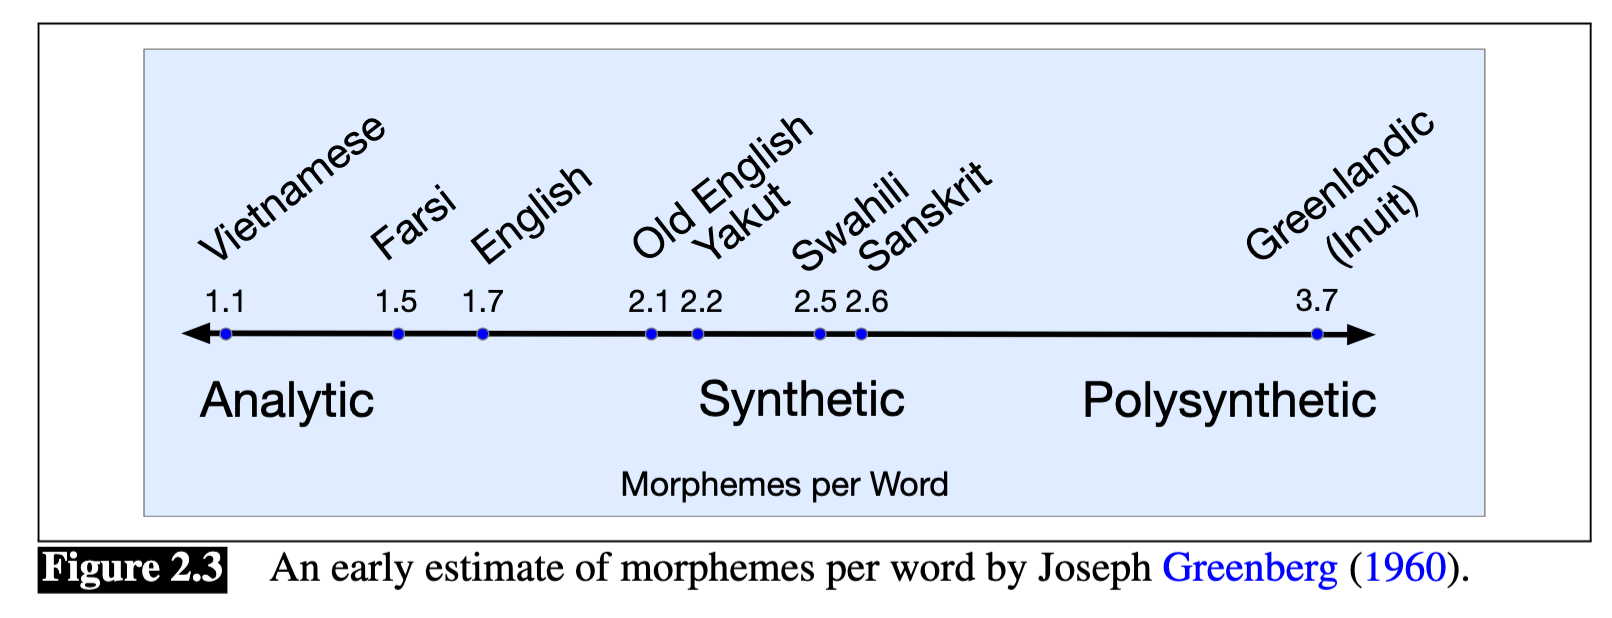

Nelle lingue **agglutinanti** i morfemi tendono a concatenarsi con confini relativamente riconoscibili; nelle lingue **fusionali** un affisso può esprimere più tratti grammaticali insieme. Per esempio, in `she reads`, `-s` marca la terza persona singolare del presente.

Queste categorie aiutano a capire perché un vocabolario di sole parole può crescere rapidamente in alcune lingue. Non implicano però che i confini morfologici siano lo standard corretto per ogni tokenizer: un'applicazione può preferire parole, subword o caratteri in base al compito.

### Esercizio 5 — scegli la convenzione per trattini e apostrofi
Prendete le frasi: `"l'acqua"`, `"no-non"`, `"caffe\u0301"`, `"café"`, `"e-mail"`, `"e-mailing"`.

1. Decidete quale convenzione volete usare per apostrofi e trattini: li tenete dentro la parola o li separate?
2. Scrivete la regola in Python con una regex e testatela su tutte le frasi.
3. Dite quali casi sono problematici per un sistema di count o per un chatbot e perché.

### Esercizio 6 — confronto tra forme e punteggiatura
Usando `tokenizza_con_regole`, costruite un mini-corpus composto da almeno 4 frasi, includendo: un apostrofo, un trattino, una maiuscola iniziale, una parola con accentazione e un segno di punteggiatura finale.

1. Calcolate occorrenze e tipi senza normalizzazione.
2. Ripetete il conteggio con `casefold()` e con `unicodedata.normalize("NFC", ...)`.
3. Spiegate quali distinzioni sono perse e quale alternativa conservereste in un sistema di riconoscimento di nomi propri.

## Tokenizzazione con NLTK

NLTK è una libreria Python per il trattamento del linguaggio naturale. Il suo tokenizer richiede l'installazione del pacchetto e, a seconda della versione, i dati Punkt (`punkt` o `punkt_tab`). La cella seguente è facoltativa: il percorso principale del notebook usa soltanto la libreria standard e non richiede download.

In [ ]:
# Dopo aver installato NLTK e scaricato i dati Punkt adatti alla versione:
# import nltk
# nltk.download("punkt_tab")  # per versioni recenti; versioni precedenti usano "punkt"
# from nltk.tokenize import word_tokenize
# testo = "Ciao, come va oggi? Bene!"
# print(word_tokenize(testo, language="italian"))

### Esercizio 7 — confronto con NLTK
Con NLTK (se è installato), tokenizzate `L'auto di Marco è rossa, vero?`. Confrontate l'output con `tokenizza_con_regole`: annotate dove separano diversamente apostrofo, virgola e punto interrogativo. Se non avete installato NLTK, usate l'esempio con spaCy o discutete l'output atteso senza installare pacchetti.

## Tokenizzazione con spaCy


spaCy è una libreria NLP che include regole specifiche per lingua e componenti di pipeline. Per usare il modello italiano si installano spaCy e `it_core_news_sm`; non sono dipendenze necessarie per seguire le attività precedenti. Il tokenizzatore si può usare anche senza eseguire tutte le componenti linguistiche.

Il codice seguente è facoltativo e presuppone che pacchetto e modello siano già installati:

In [ ]:
# import spacy
# nlp = spacy.load("it_core_news_sm")
# testo = "Ciao, come va oggi? Bene!"
# doc = nlp.make_doc(testo)  # esegue la sola tokenizzazione
# print([token.text for token in doc])

### Esercizio 8 — confronto con spaCy
Se spaCy e il modello italiano sono disponibili, tokenizzate una frase a scelta. Selezionate una frase con apostrofo, trattino, numero e punteggiatura. Confrontate i token con la regex di questo notebook: non decidete quale sia "giusto" in astratto; valutate quale convenzione serve al vostro task.

## Tokenizzazione di frasi

La segmentazione può riguardare anche le frasi. Una regola ingenua che divide dopo `.`, `?` o `!` è utile per iniziare, ma può sbagliare su abbreviazioni (`dott.`), iniziali, decimali e citazioni. Le librerie usano regole o modelli più ricchi; anche qui il risultato dipende dalla lingua e dal dominio.

In [ ]:
testo = "Ciao! Come va? Oggi è una bella giornata."
frasi = re.split(r"(?<=[.!?])\s+", testo)
print(frasi)

### Esercizio 9 — trova il limite della regola
Provate la funzione su `"Ciao! Come va? Oggi è una bella giornata."` e su `"Il dott. Rossi arriva alle 9.30. Poi parlerà."`. La regola conta bene le frasi in entrambi i casi? Spiegate l'errore e proponete un test che una libreria dovrebbe superare.

### Esercizio 10 — analisi degli errori e mini-laboratorio finale

A coppie, definite un compito (per esempio conteggio di parole, ricerca di nomi, chatbot o analisi di recensioni) e costruite una mini-collezione di almeno 5 frasi, includendo apostrofi, punteggiatura, una forma nuova e un'esitazione o un trattino.

1. Scrivete la convenzione scelta per token e normalizzazione.
2. Applicate `split()` e `tokenizza_con_regole`; confrontate i risultati su almeno 3 esempi.
3. Segnate almeno 3 errori o differenze e classificate la causa: confini, maiuscole/Unicode, punteggiatura, lingua o dominio.
4. Calcolate occorrenze e tipi per una versione dei dati; spiegate cosa cambia applicando `casefold()`.
5. Presentate un caso OOV e valutate una soluzione (token sconosciuto o subword).

Scrivete il codice, le convenzioni esplicite e una breve motivazione della scelta del tokenizer per il compito. Non serve installare librerie esterne.